# Stage 4: SHAP Interpretation

This notebook reads the Stage 4 tables. The model is a composition-only predictor of yield strength. SHAP attributes the prediction. It does not prove a strengthening mechanism.

The headline model is the default random forest on the 13 non-iron weight percents. A consistent or inconsistent label is kept only when that forest, the tuned forest, and tuned XGBoost agree.


In [1]:
import pandas as pd
from IPython.display import Image, display
metrics = pd.read_csv('../results/stage4_nofe_cv_metrics.csv')
paired = pd.read_csv('../results/stage4_nofe_paired_tests.csv')
sanity = pd.read_csv('../results/stage4_metallurgical_sanity.csv')
display(metrics)
display(paired)
display(sanity[['element', 'consensus', 'headline_rho', 'vote_default_rf_13', 'vote_tuned_rf_13', 'vote_tuned_xgb_13', 'reason']])


,model,rmse_mean,rmse_std,mae_mean,mae_std,r2_mean,r2_std
0,default_rf_13,156.526217,26.924377,116.144195,21.624926,0.700432,0.121214
1,default_rf_14,160.284773,27.405039,118.648753,22.278482,0.684980,0.128010
2,tuned_rf_13,157.595629,26.811771,118.035043,20.777457,0.700347,0.113058
3,tuned_rf_14,161.749310,28.743698,120.240075,22.026536,0.682603,0.124811
4,tuned_xgb_13,160.309192,26.522216,118.337759,20.741173,0.685549,0.128026
5,tuned_xgb_14,160.678573,26.543645,118.310797,21.218854,0.685241,0.125825


,comparison,mean_delta_rmse_mpa,ci95_low,ci95_high,p_corrected,n_train_mean,n_test_mean
0,default_rf_13 minus default_rf_14,-3.758556,-9.410554,1.893441,0.182604,249.6,62.4
1,tuned_rf_13 minus tuned_rf_14,-4.153681,-12.265688,3.958326,0.301125,249.6,62.4
2,tuned_xgb_13 minus tuned_xgb_14,-0.369381,-10.616938,9.878176,0.941313,249.6,62.4


,element,consensus,headline_rho,vote_default_rf_13,vote_tuned_rf_13,vote_tuned_xgb_13,reason
0,Al,consistent,0.411489,consistent,consistent,consistent,"Where nickel is at least 12 wt%, higher alumin..."
1,C,unclear,0.438462,unclear,unclear,unclear,"No sign was declared before the run, so the me..."
2,Co,consistent,0.787425,consistent,consistent,consistent,Higher concentration receives positive SHAP gl...
3,Cr,unclear,-0.651949,unclear,unclear,unclear,The chromium pattern does not match the predec...
4,Fe,unclear,NaN,unclear,unclear,unclear,"Iron closes the composition, so this attributi..."
5,Mn,unclear,0.164579,unclear,unclear,unclear,"No sign was declared before the run, so the me..."
6,Mo,unclear,-0.382012,unclear,unclear,unclear,Mean absolute SHAP is below the median element...
7,N,unclear,-0.274854,unclear,unclear,unclear,Present in under 20% of alloys. The attributio...
8,Nb,unclear,-0.818167,unclear,unclear,unclear,"No sign was declared before the run, so the me..."
9,Ni,unclear,0.835270,unclear,consistent,consistent,The three 13-feature models do not agree: defa...


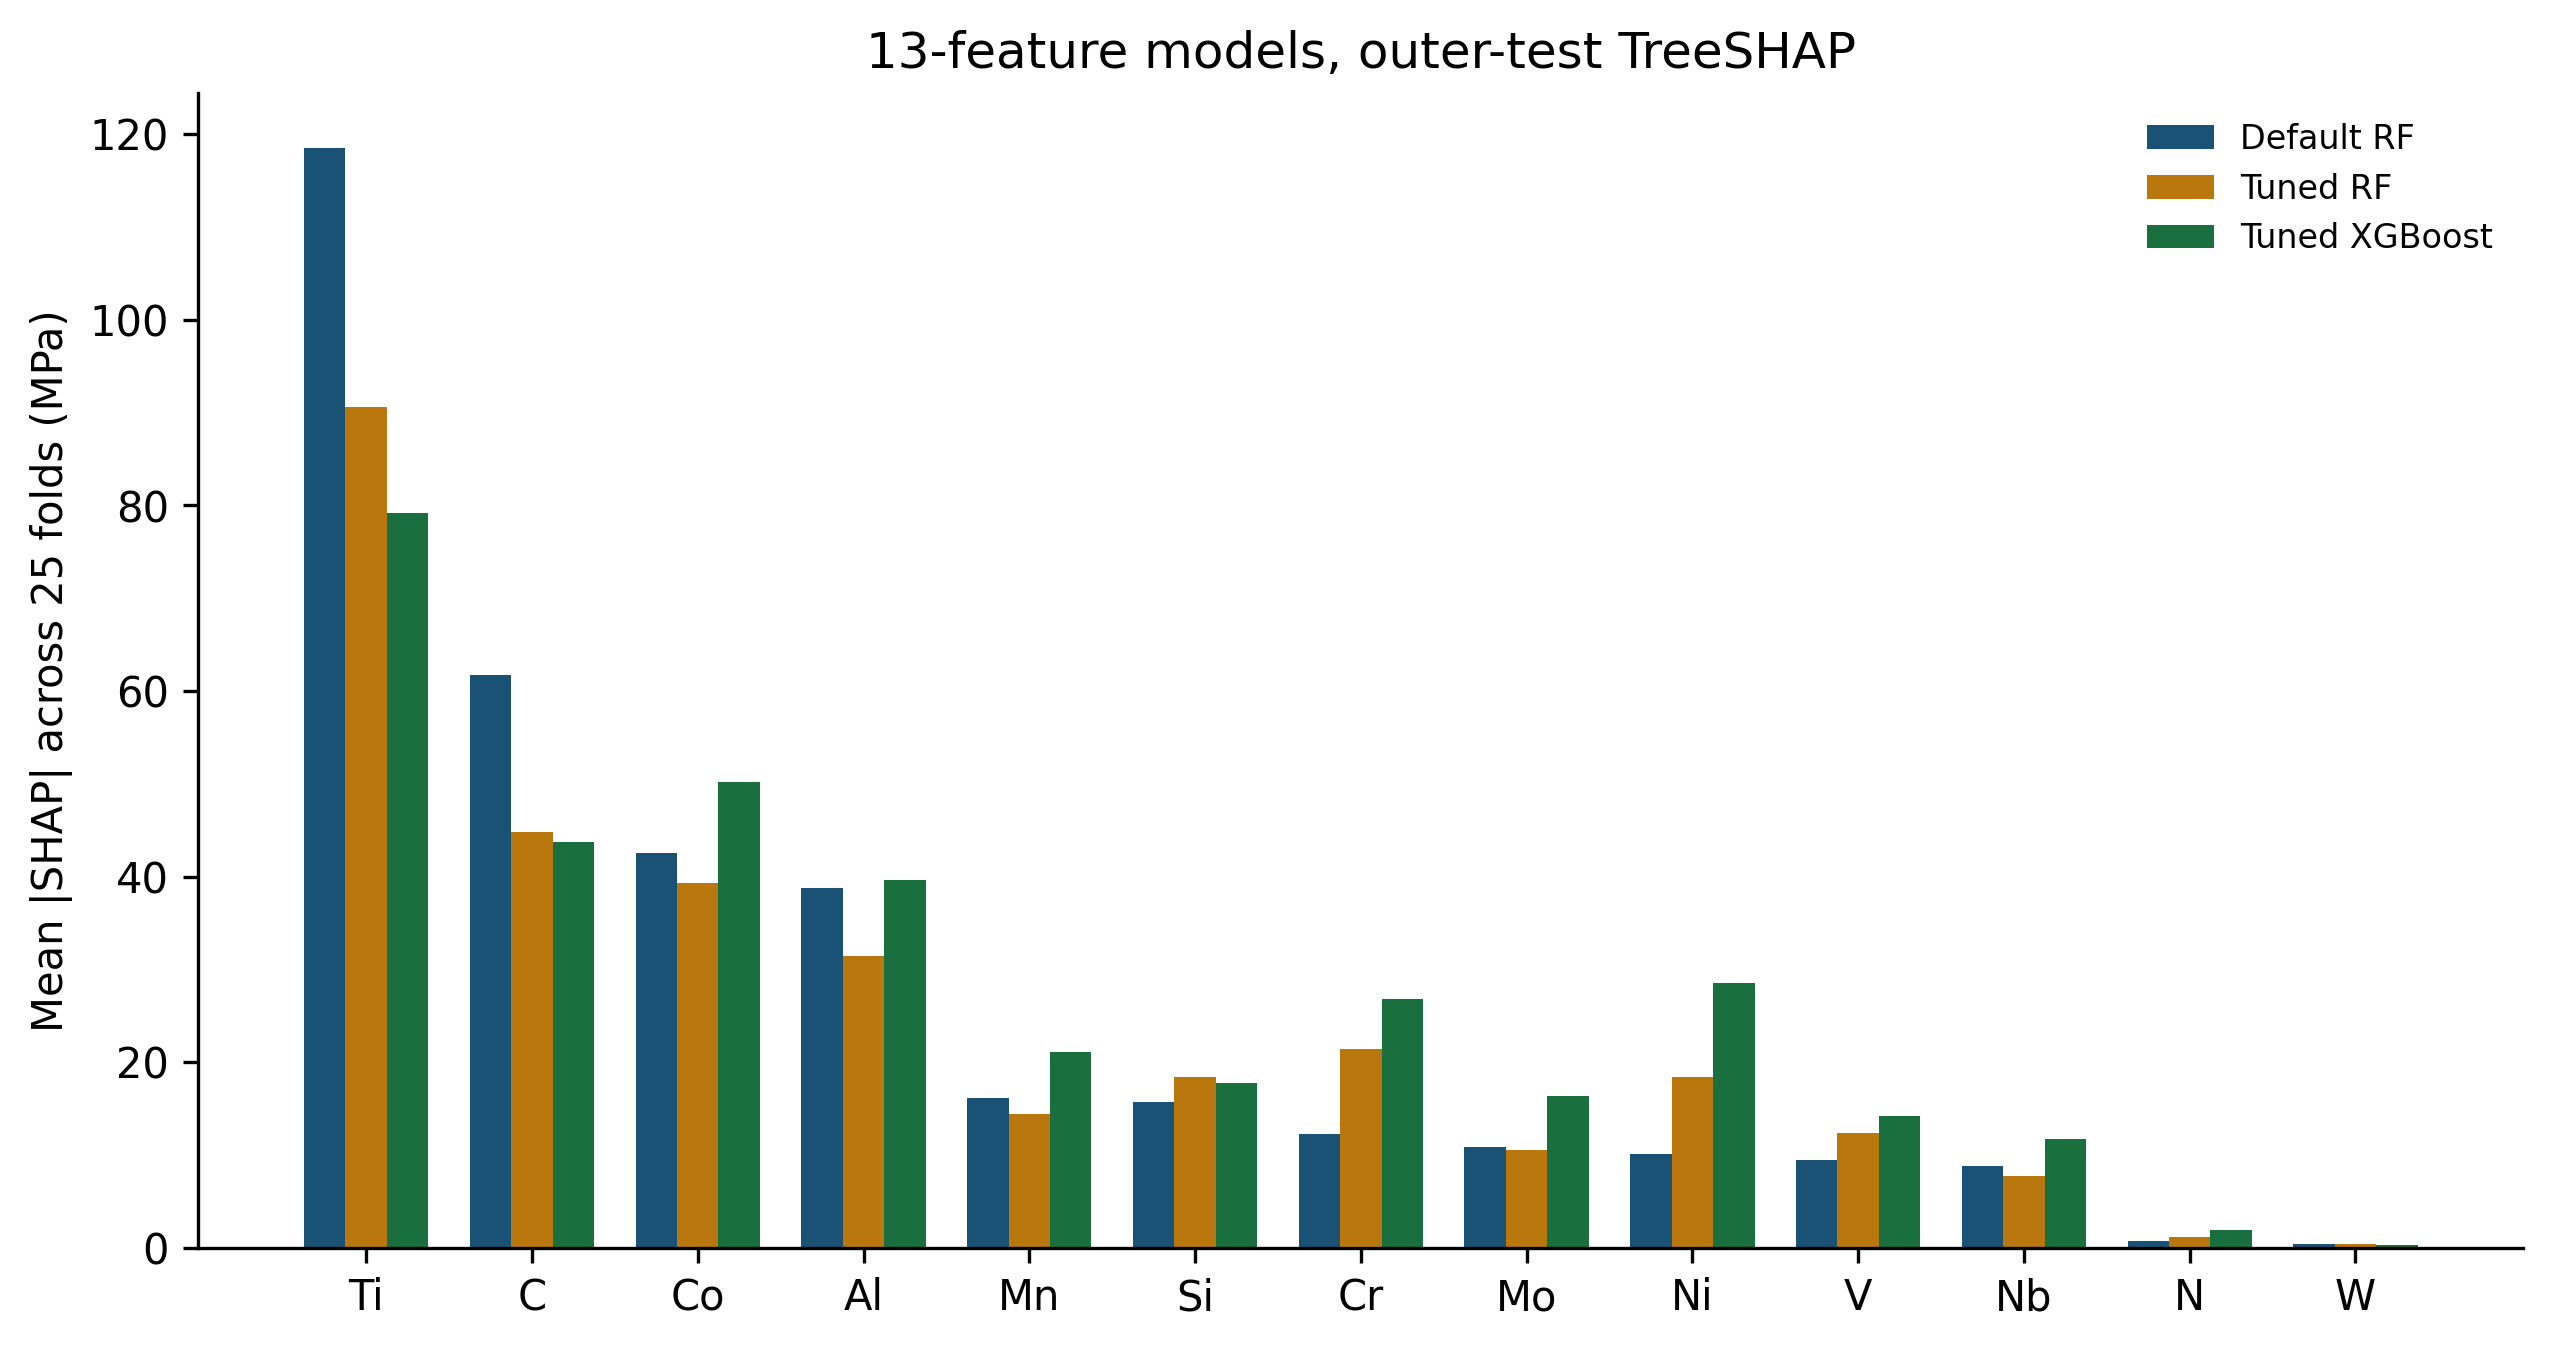

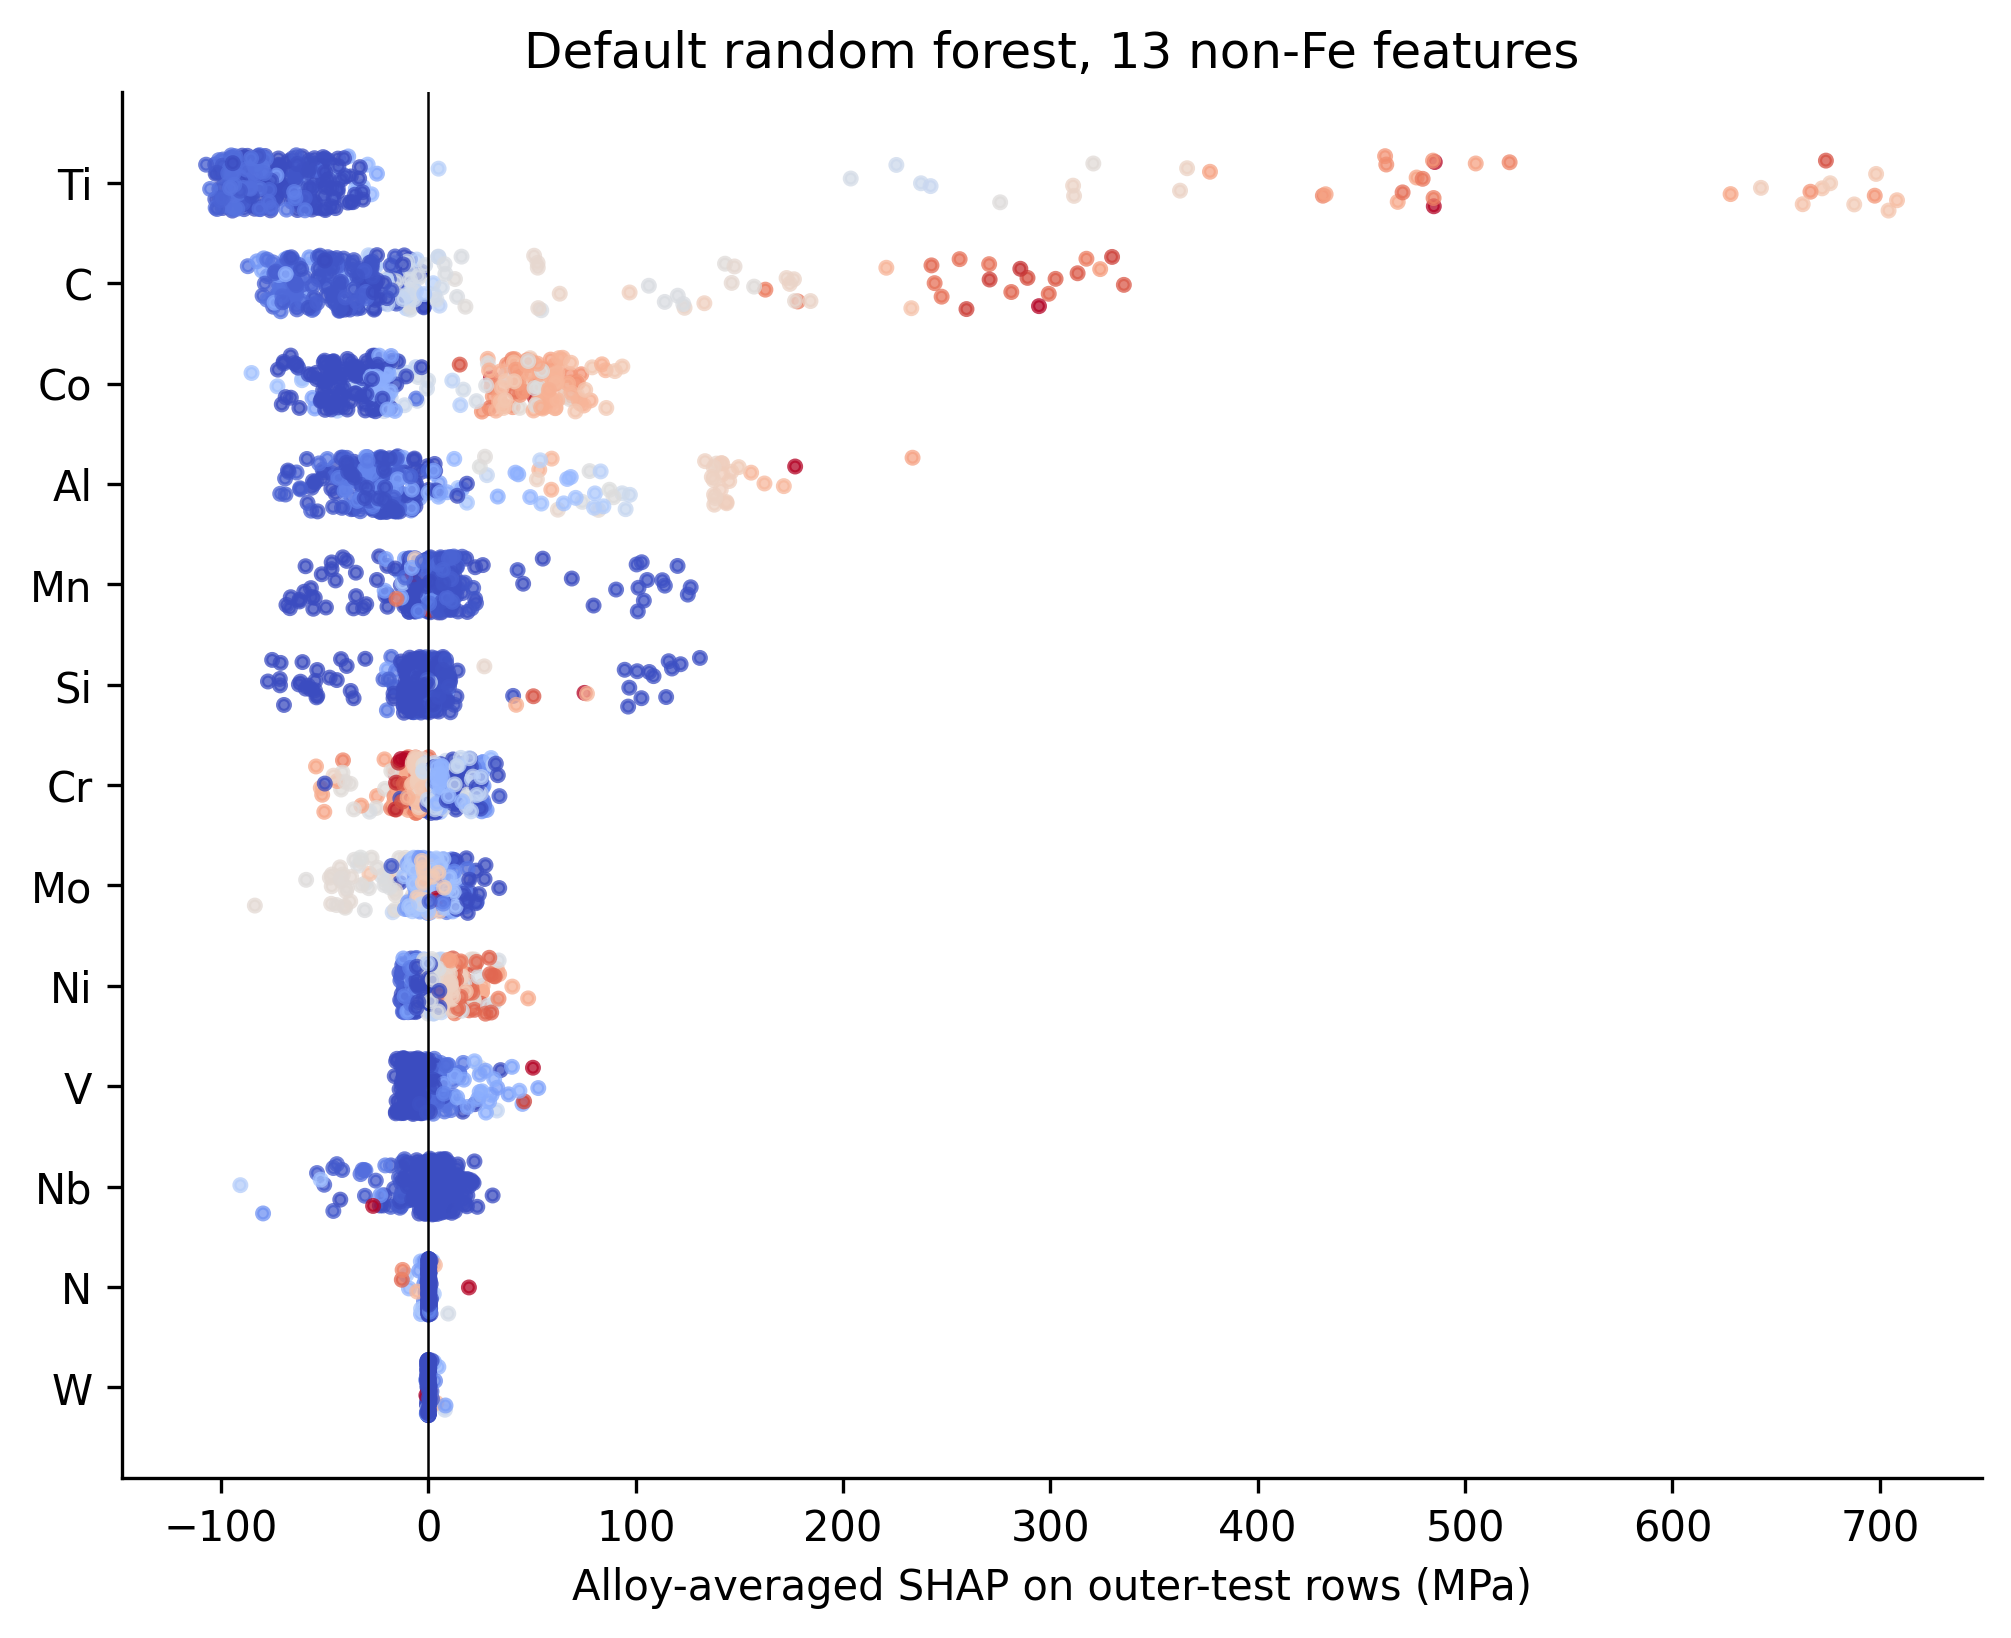

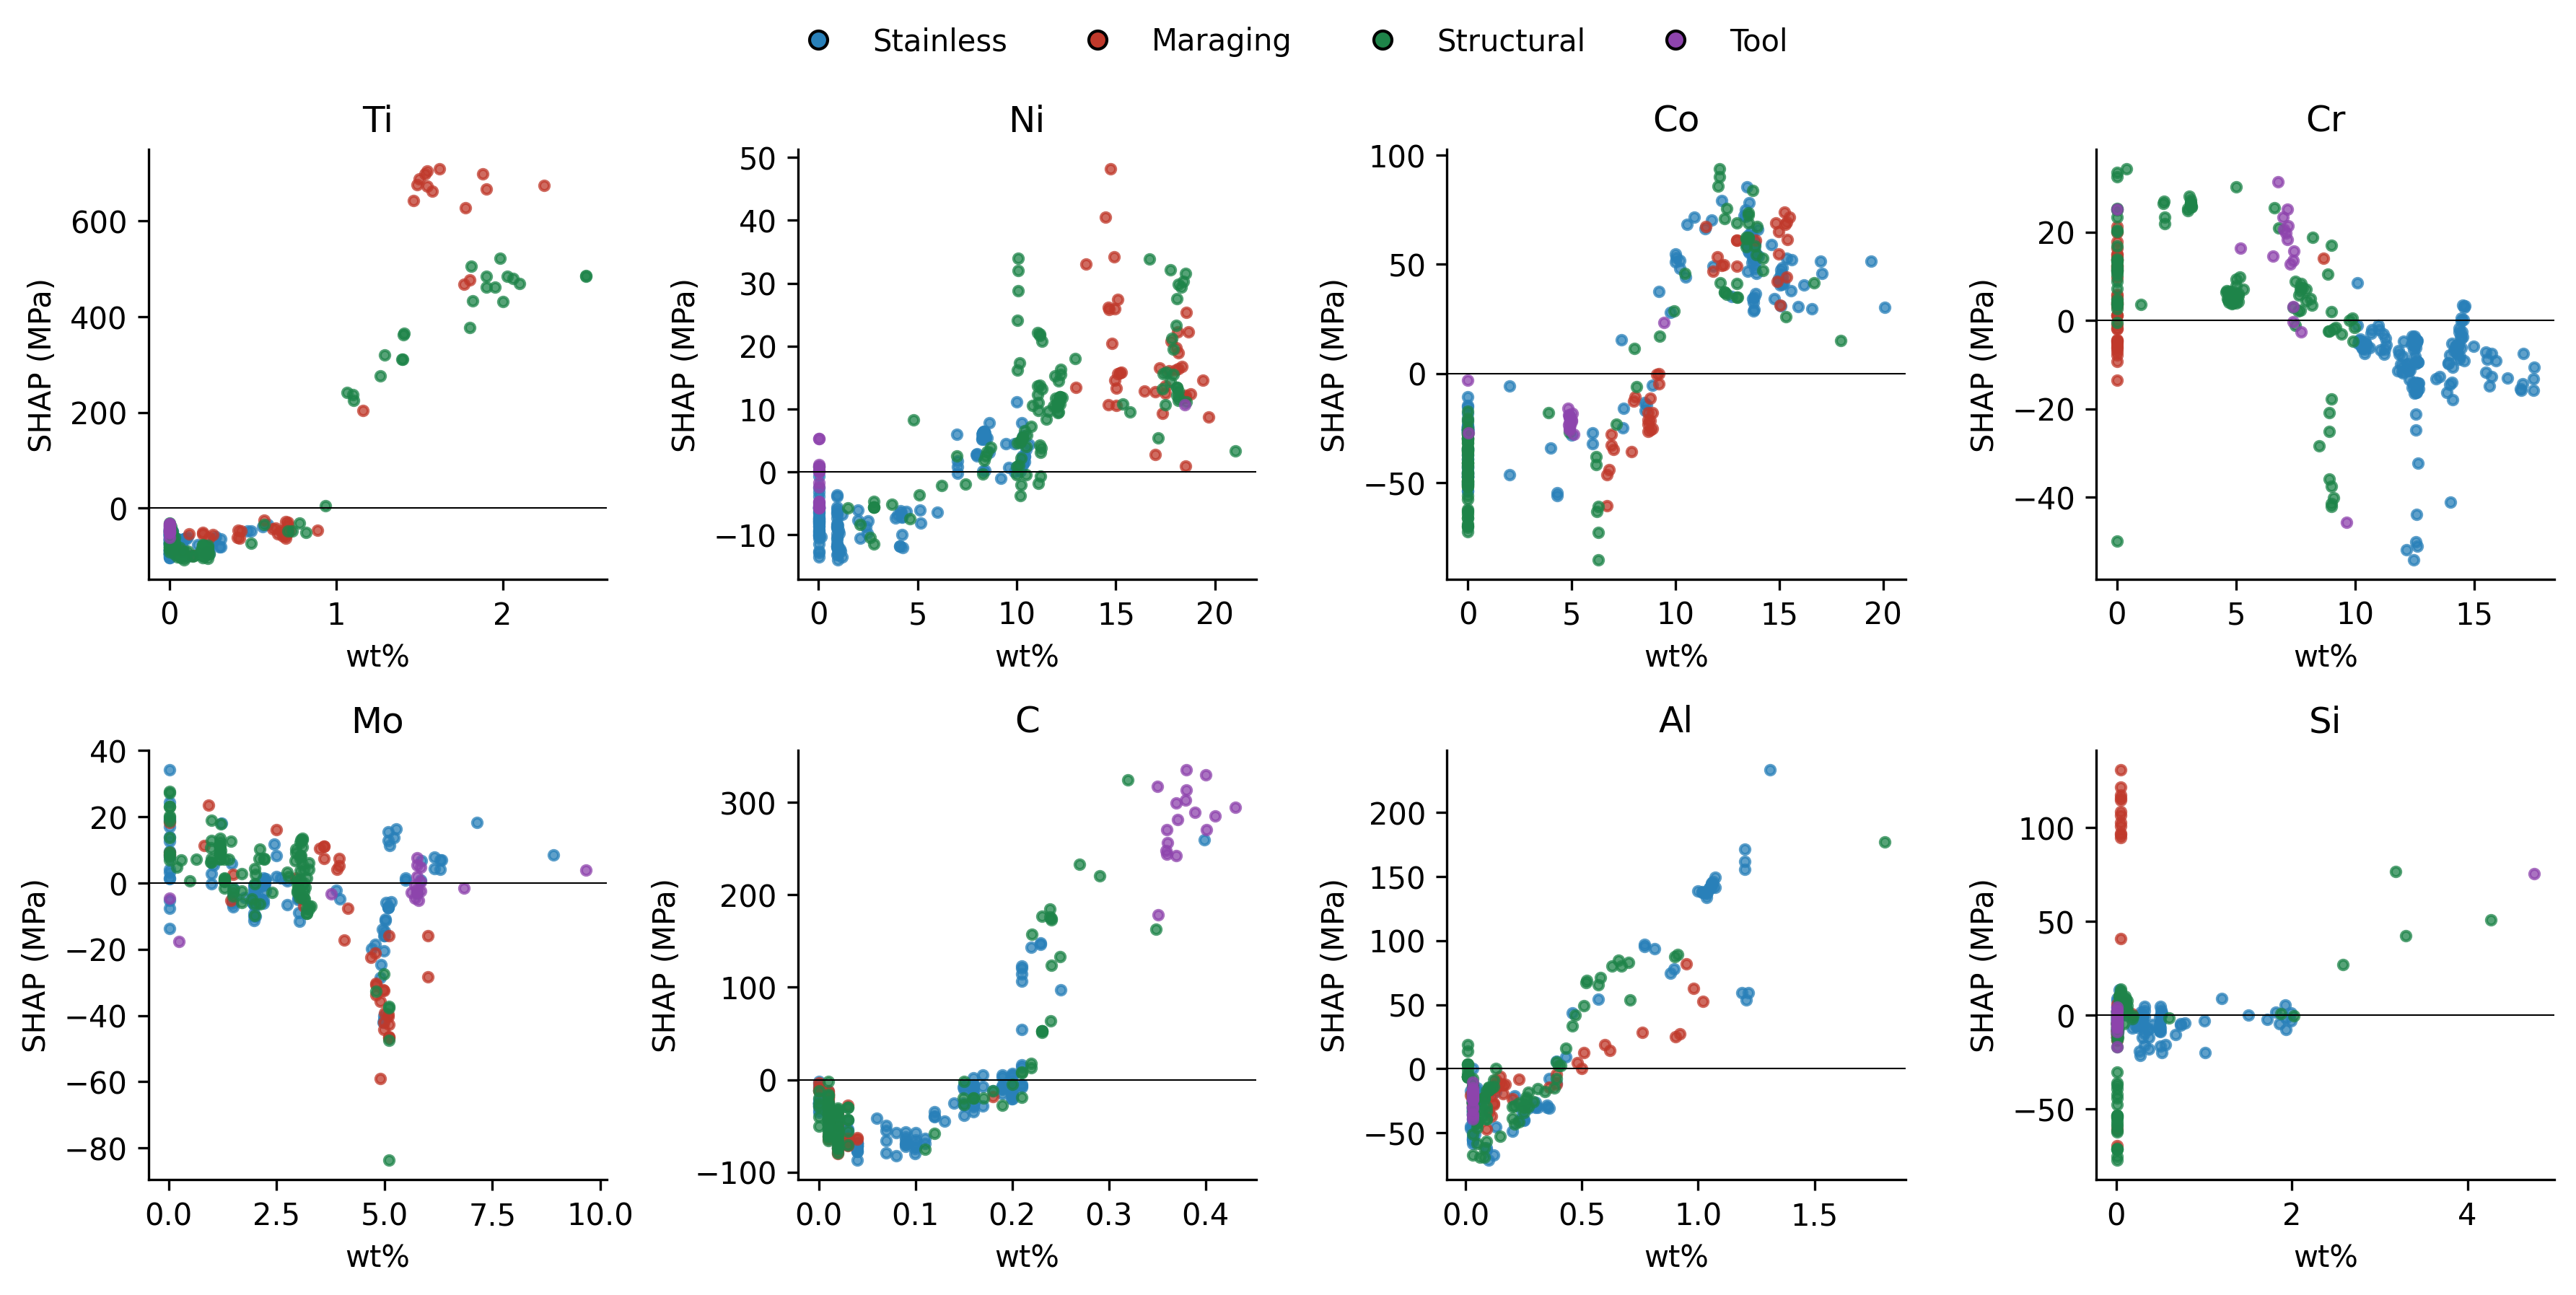

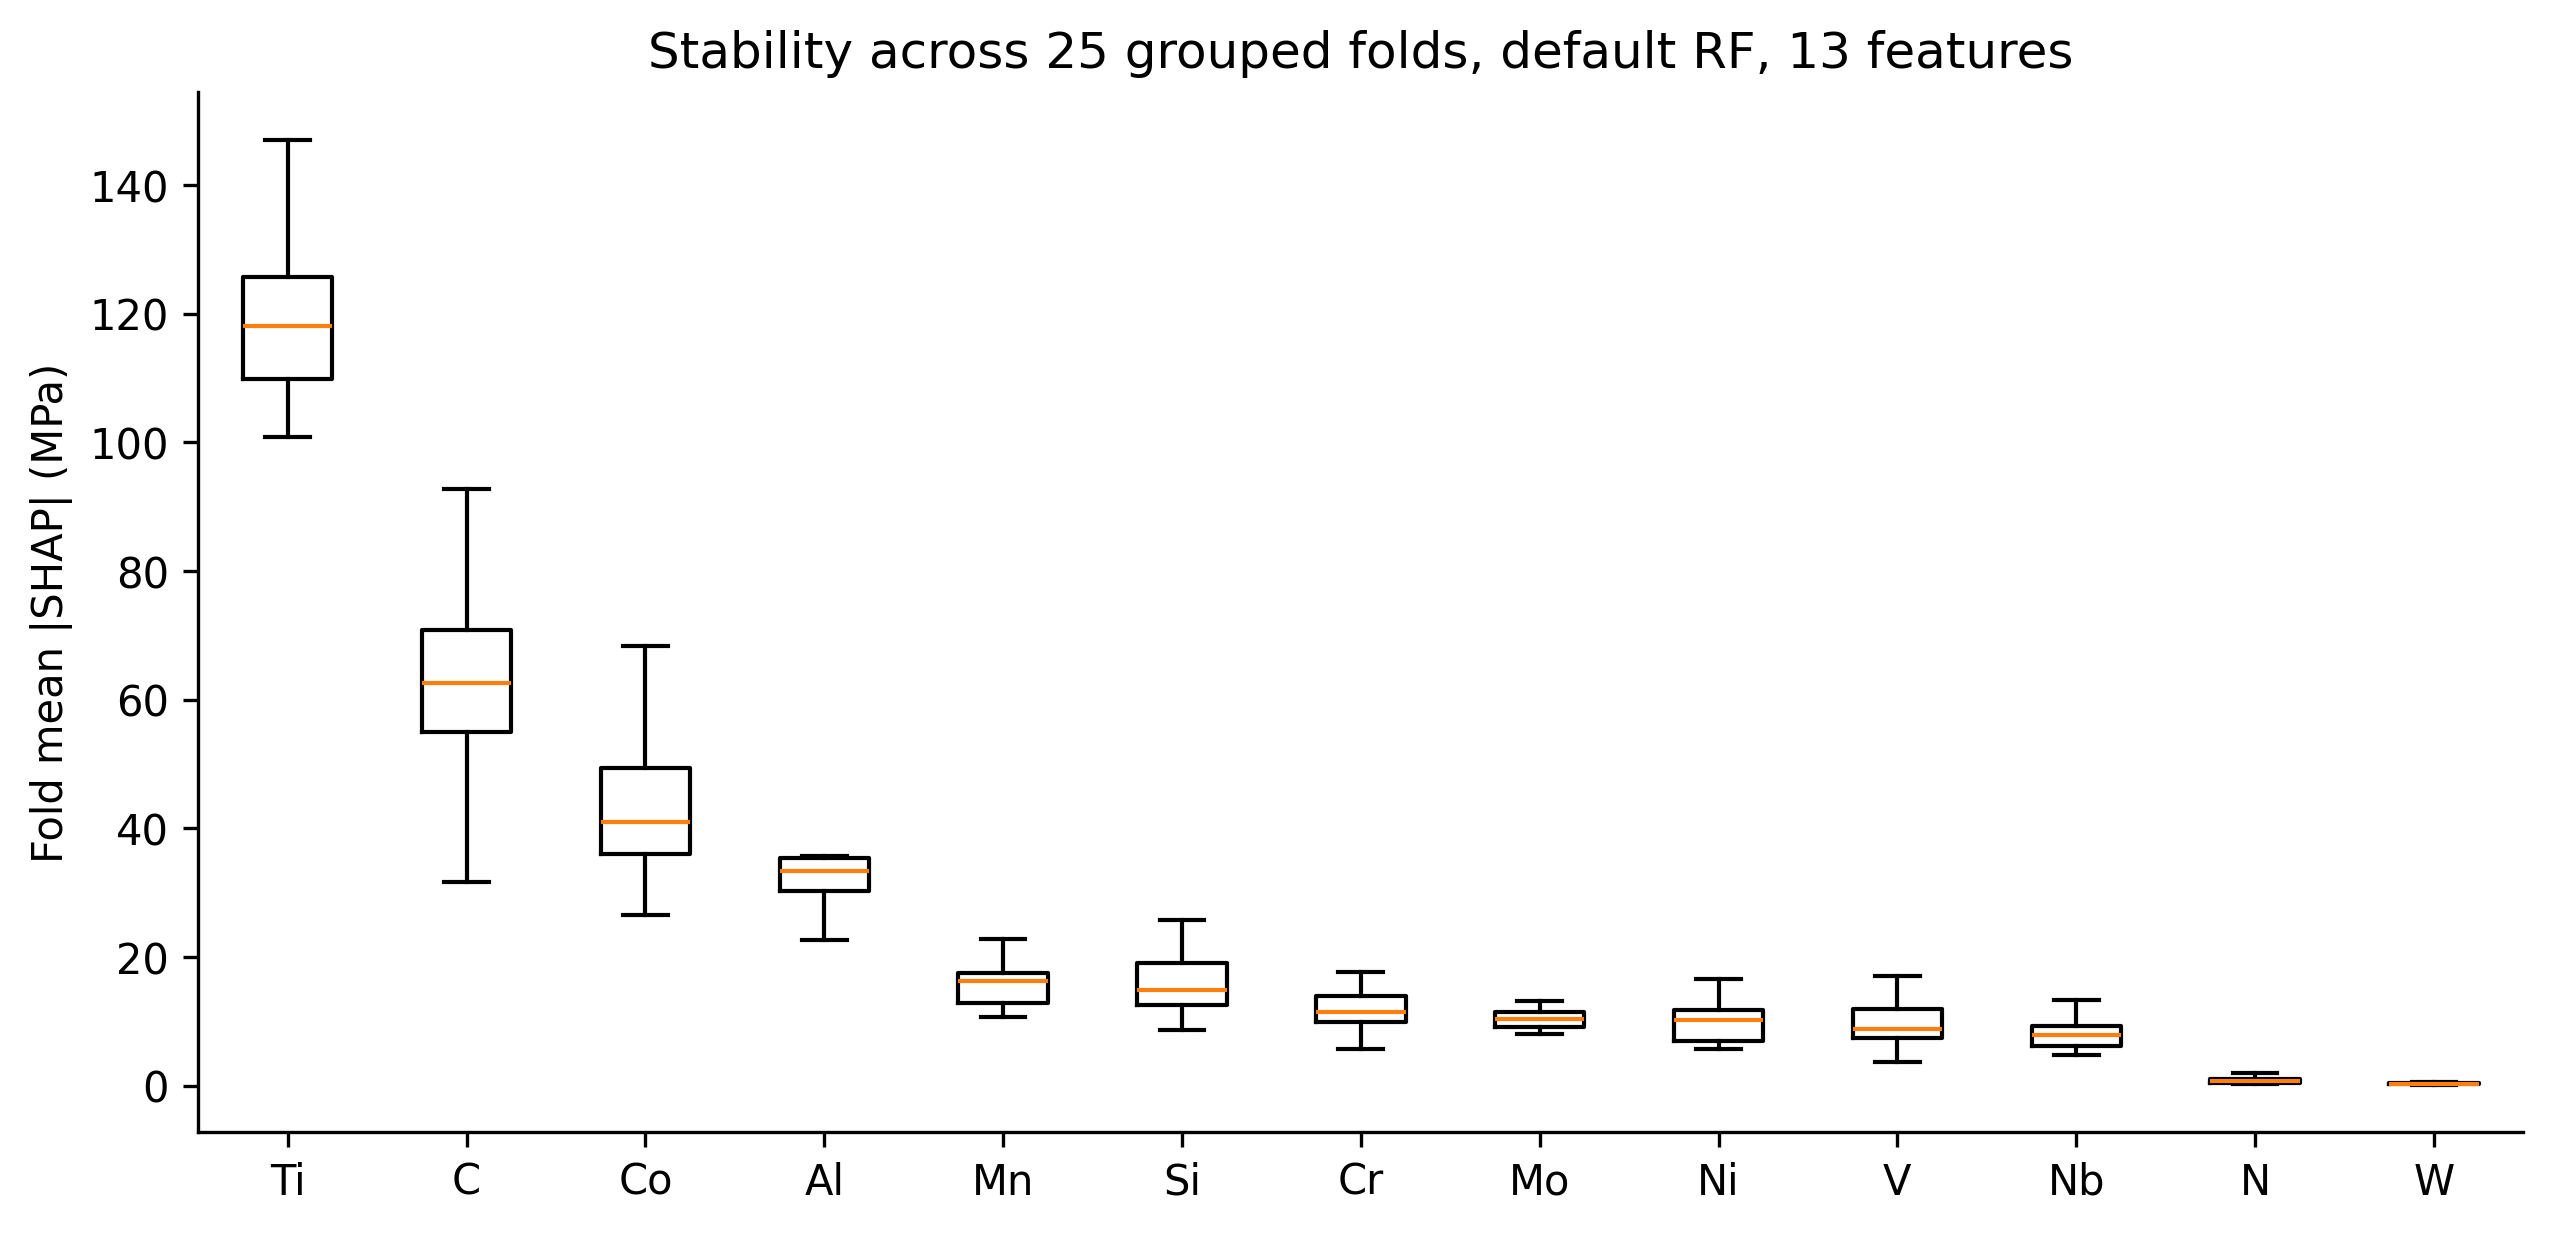

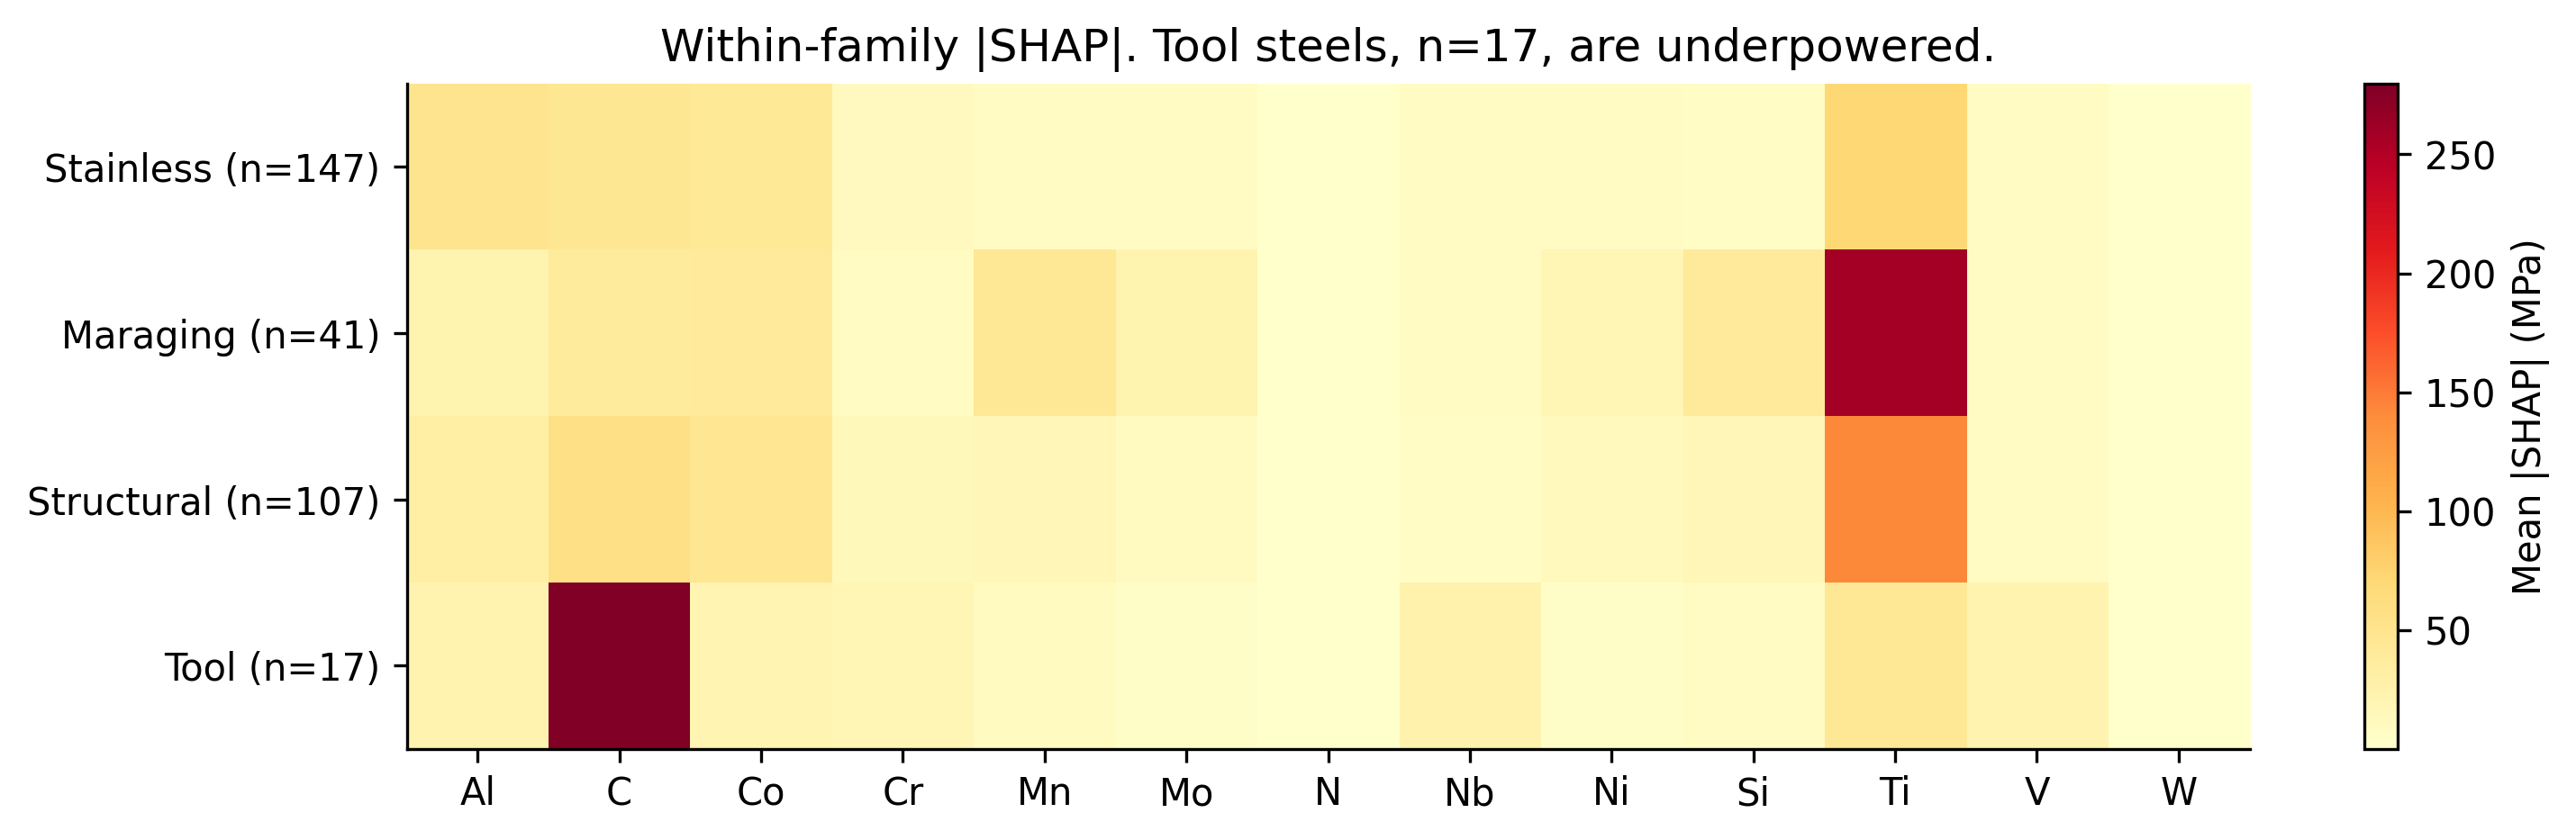

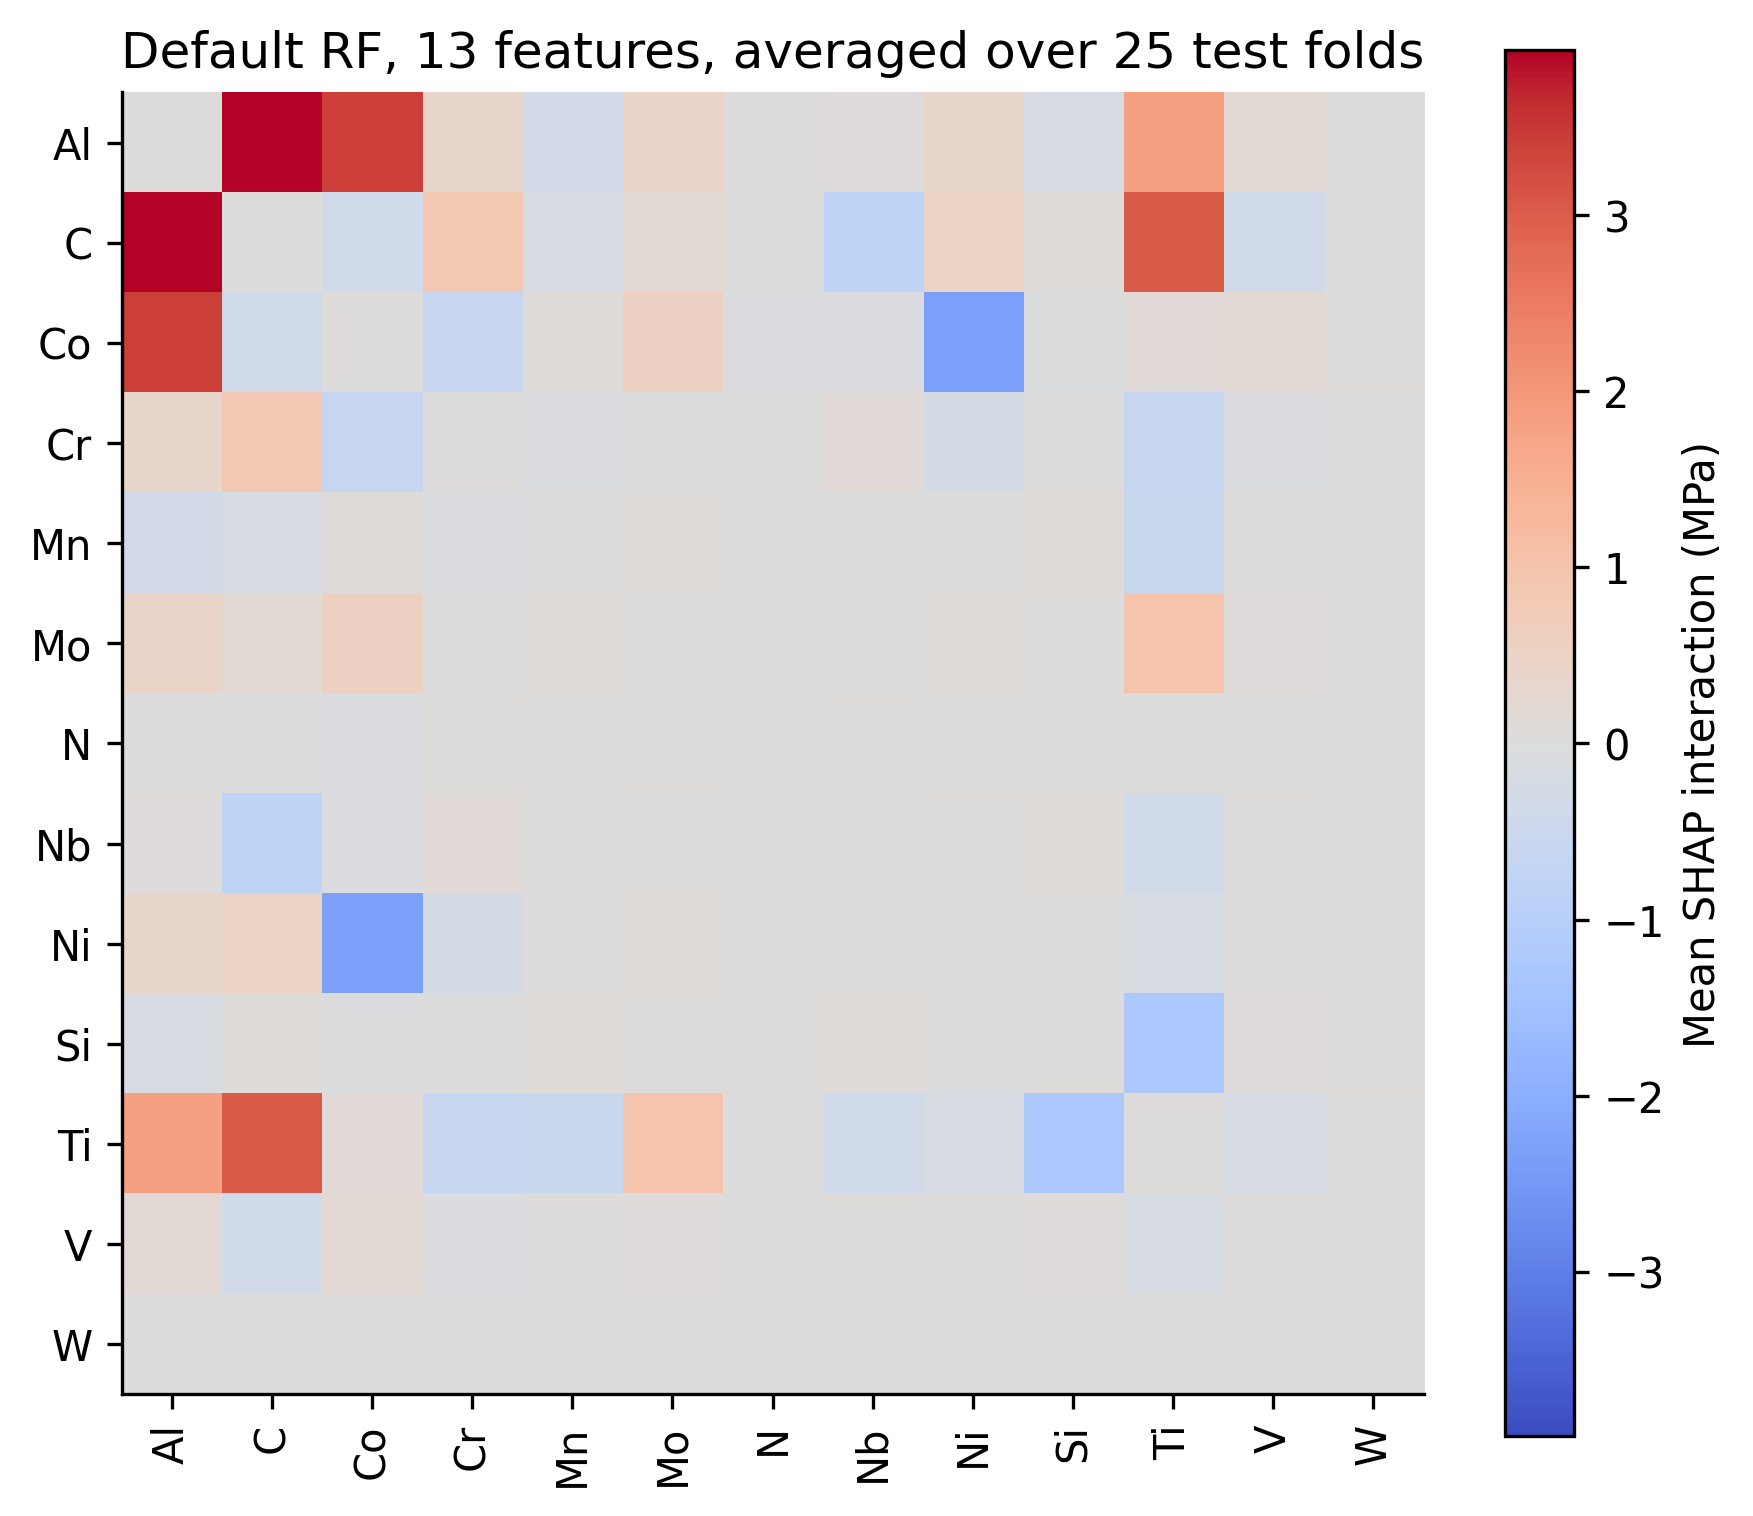

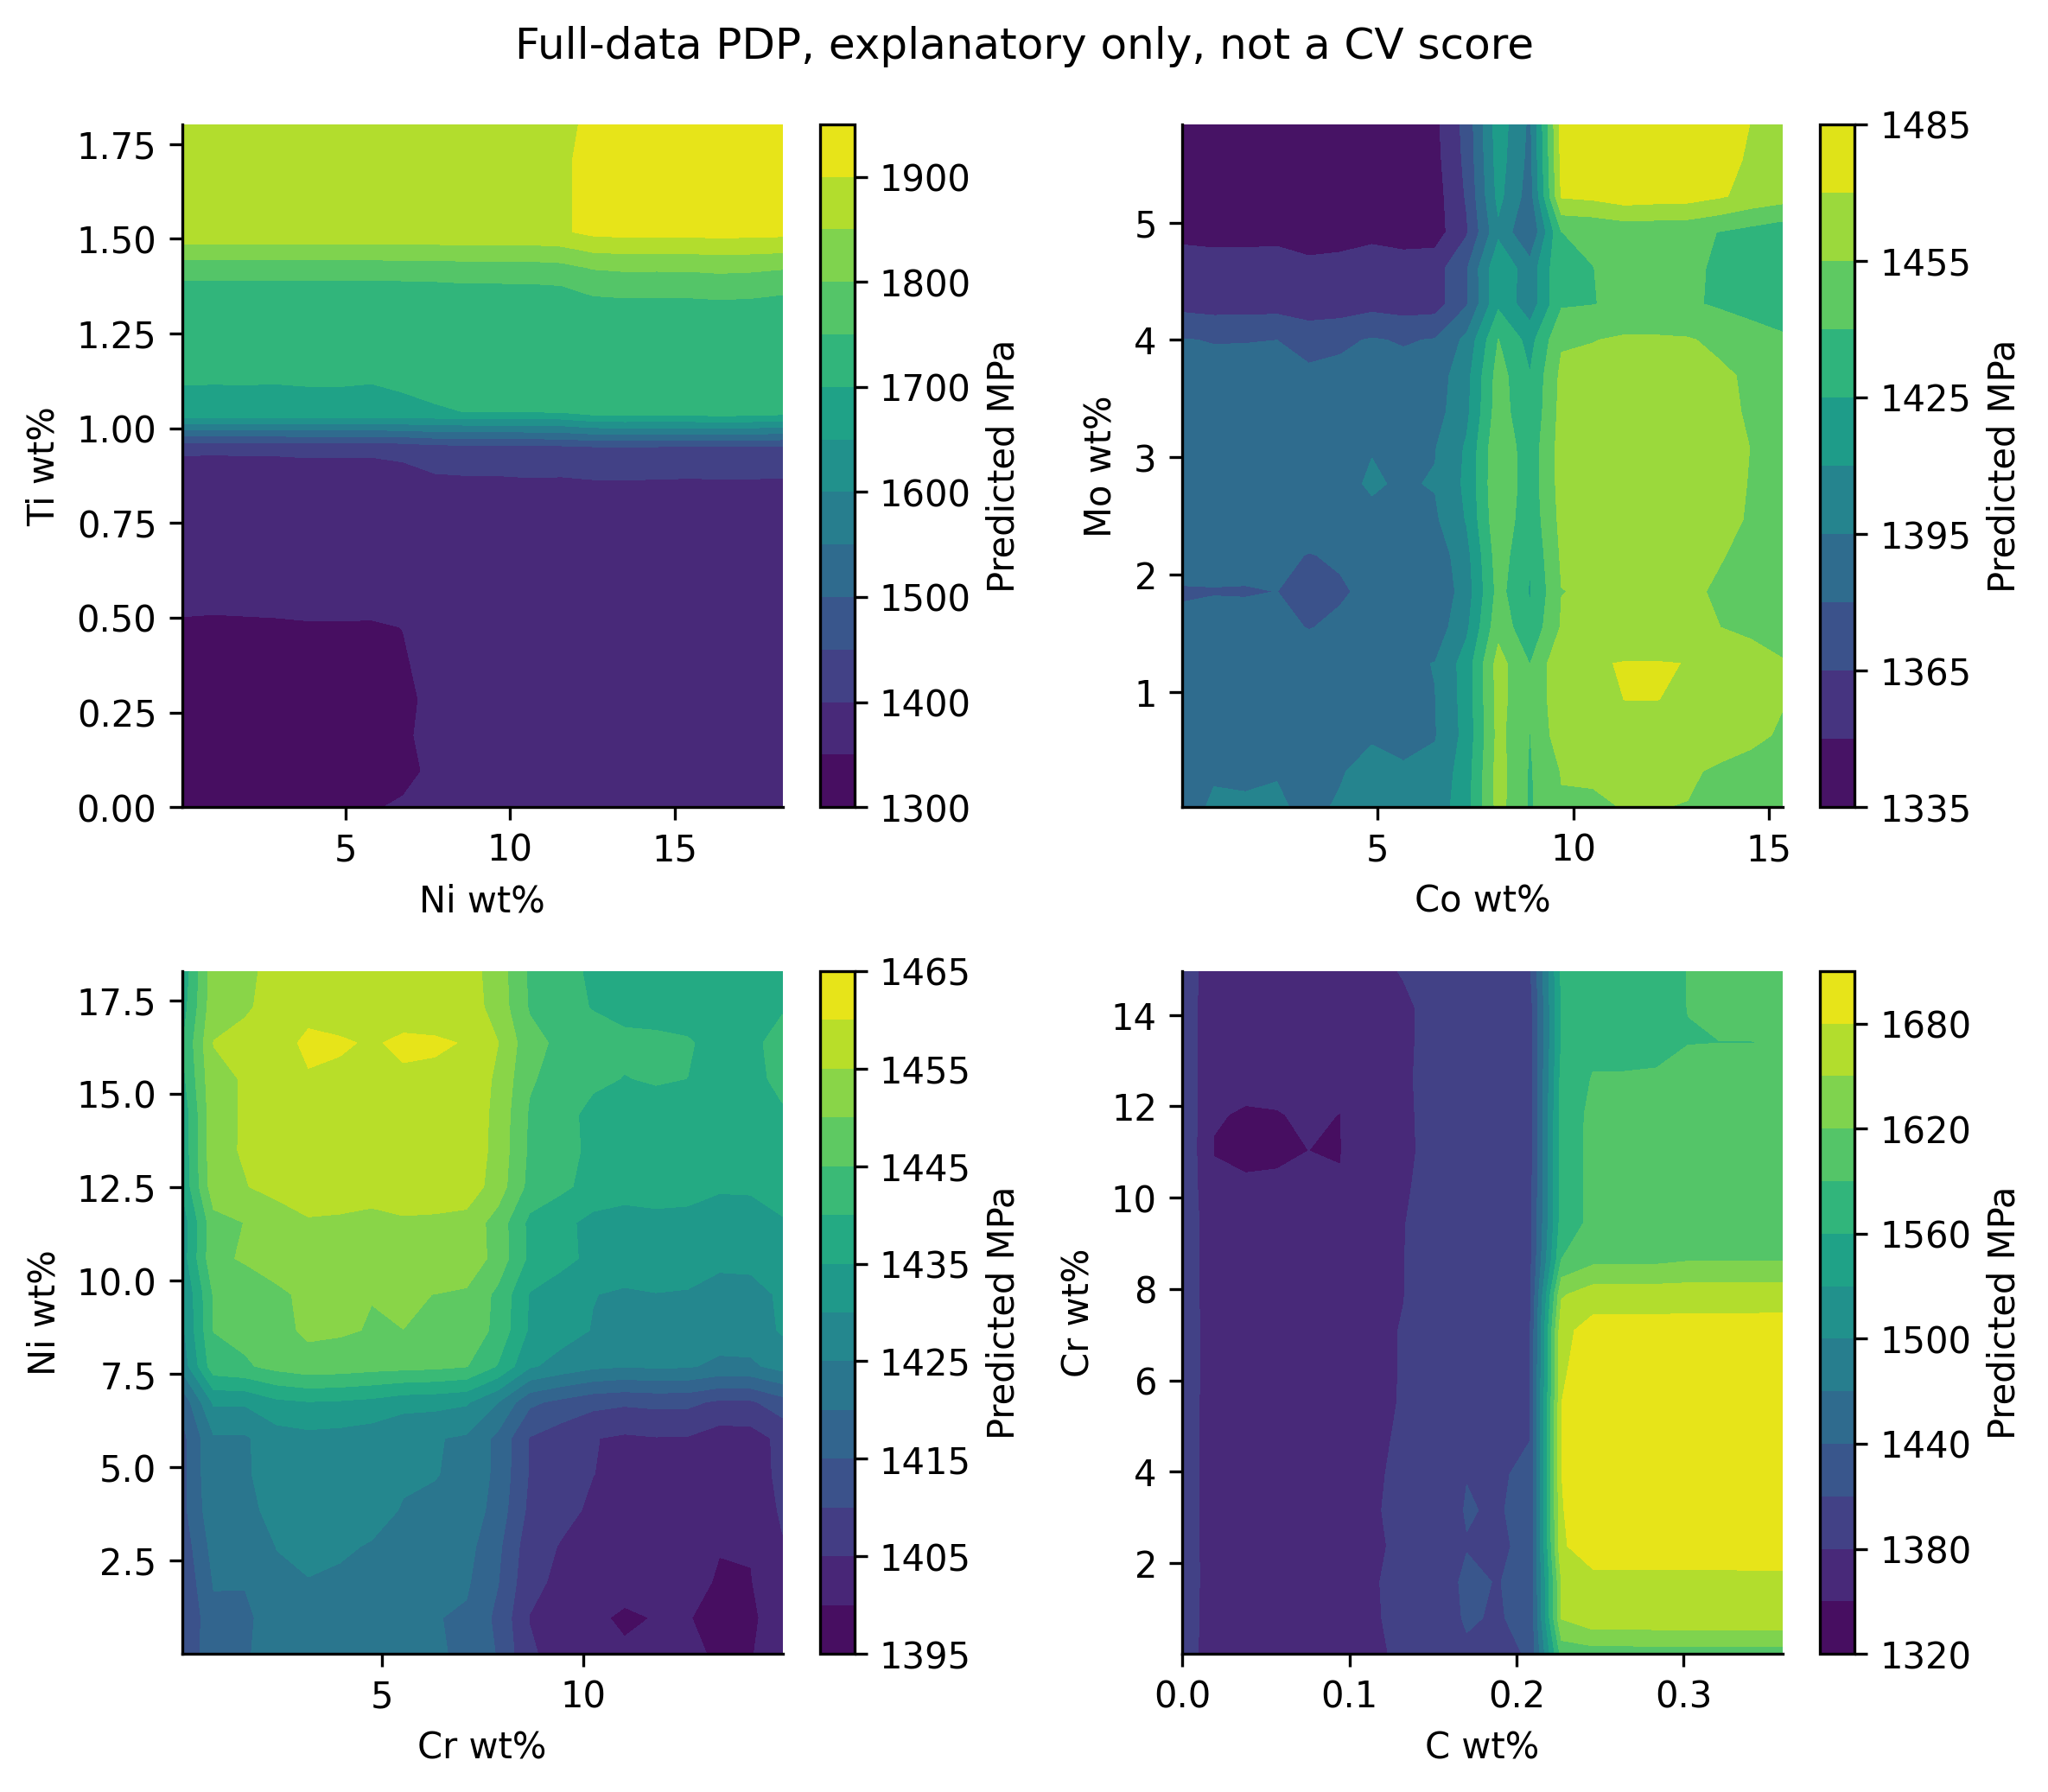

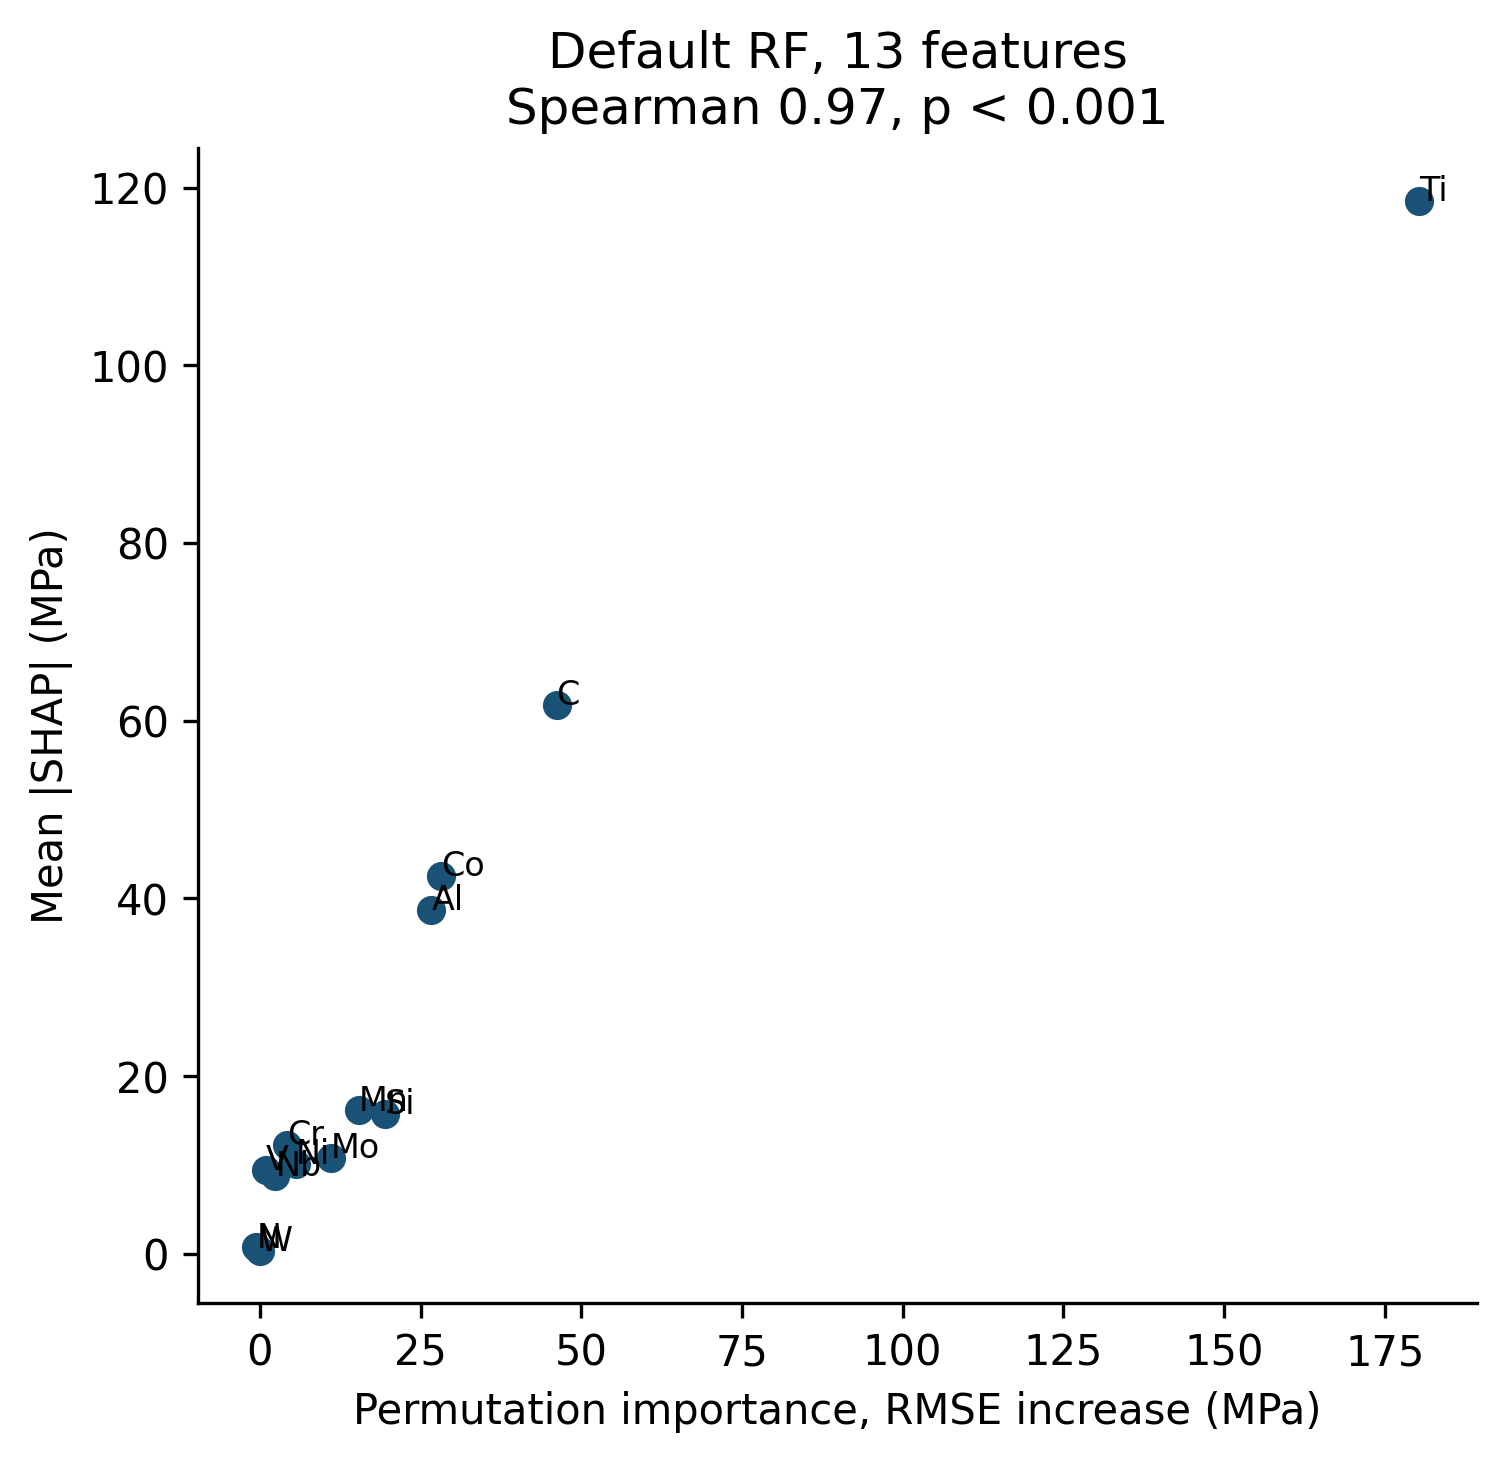

In [2]:
for name in [
    'fig14_shap_importance_bars.png',
    'fig15_shap_beeswarm_default_rf.png',
    'fig16_shap_dependence.png',
    'fig17_shap_stability_folds.png',
    'fig18_shap_family_heatmap.png',
    'fig19_shap_interactions.png',
    'fig20_partial_dependence_pairs.png',
    'fig21_shap_vs_permutation.png',
]:
    display(Image(filename=f'../figures/{name}'))
